In [5]:
import pandas as pd


data = pd.read_csv('stock_day.csv')
# 删除某些列  在原来的data基础上生效 相当于直接修改原始数据
data.drop(['ma5','ma10','ma20','v_ma5','v_ma10','v_ma20'],axis=1,inplace=True)
data.head()

,open,high,close,low,volume,price_change,p_change,turnover
2018-02-27,23.53,25.88,24.16,23.53,95578.03,0.63,2.68,2.39
2018-02-26,22.80,23.78,23.53,22.80,60985.11,0.69,3.02,1.53
2018-02-23,22.88,23.37,22.82,22.71,52914.01,0.54,2.42,1.32
2018-02-22,22.25,22.76,22.28,22.02,36105.01,0.36,1.64,0.90
2018-02-14,21.49,21.99,21.92,21.48,23331.04,0.44,2.05,0.58


In [12]:
data[(data['open'] > 20) & (data['high'] < 50)].head()  # 逻辑运算 & | 两边必须用小括号

,open,high,close,low,volume,price_change,p_change,turnover
2018-02-27,23.53,25.88,24.16,23.53,95578.03,0.63,2.68,2.39
2018-02-26,22.80,23.78,23.53,22.80,60985.11,0.69,3.02,1.53
2018-02-23,22.88,23.37,22.82,22.71,52914.01,0.54,2.42,1.32
2018-02-22,22.25,22.76,22.28,22.02,36105.01,0.36,1.64,0.90
2018-02-14,21.49,21.99,21.92,21.48,23331.04,0.44,2.05,0.58


In [14]:
# query函数 能简化逻辑运算   里面的参数是一个字符串 通过列名的比较来实现逻辑运算
data.query('open > 20 & high < 50').head()

,open,high,close,low,volume,price_change,p_change,turnover
2018-02-27,23.53,25.88,24.16,23.53,95578.03,0.63,2.68,2.39
2018-02-26,22.80,23.78,23.53,22.80,60985.11,0.69,3.02,1.53
2018-02-23,22.88,23.37,22.82,22.71,52914.01,0.54,2.42,1.32
2018-02-22,22.25,22.76,22.28,22.02,36105.01,0.36,1.64,0.90
2018-02-14,21.49,21.99,21.92,21.48,23331.04,0.44,2.05,0.58


In [16]:
data['open'].isin([22.76,23.53,]).head()   # 是否在isin后面的列表里面

2018-02-27     True
2018-02-26    False
2018-02-23    False
2018-02-22    False
2018-02-14    False
Name: open, dtype: bool

In [18]:
data[data['open'].isin([22.76,23.53])].head()  # 根据isin能找到所有在isin里面的数据

,open,high,close,low,volume,price_change,p_change,turnover
2018-02-27,23.53,25.88,24.16,23.53,95578.03,0.63,2.68,2.39
2017-07-26,23.53,23.92,23.40,22.85,110276.48,-0.30,-1.27,2.76
2015-12-18,23.53,24.66,23.99,23.43,109230.05,0.65,2.79,3.74


In [19]:
# 视频16-5-5-5  统计运算   describe函数能看出很多信息
data.describe()

,open,high,close,low,volume,price_change,p_change,turnover
count,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000
mean,21.272706,21.900513,21.336267,20.771835,99905.519114,0.018802,0.190280,2.936190
std,3.930973,4.077578,3.942806,3.791968,73879.119354,0.898476,4.079698,2.079375
min,12.250000,12.670000,12.360000,12.200000,1158.120000,-3.520000,-10.030000,0.040000
25%,19.000000,19.500000,19.045000,18.525000,48533.210000,-0.390000,-1.850000,1.360000
50%,21.440000,21.970000,21.450000,20.980000,83175.930000,0.050000,0.260000,2.500000
75%,23.400000,24.065000,23.415000,22.850000,127580.055000,0.455000,2.305000,3.915000
max,34.990000,36.350000,35.210000,34.010000,501915.410000,3.030000,10.030000,12.560000


In [20]:
data.max(0)   # 里面的0代表按列    求出每列中的最大值

open                34.99
high                36.35
close               35.21
low                 34.01
volume          501915.41
price_change         3.03
p_change            10.03
turnover            12.56
dtype: float64

In [22]:
data.max(1).head()   # 里面的1代表按行求最大值 

2018-02-27    95578.03
2018-02-26    60985.11
2018-02-23    52914.01
2018-02-22    36105.01
2018-02-14    23331.04
dtype: float64

In [23]:
data.sum(axis=0).head()   # 按列求和

open         13678.35
high         14082.03
close        13719.22
low          13356.29
volume    64239248.79
dtype: float64

In [24]:
data.idxmax(axis=0)   # 按列求出最大值的索引 

open            2015-06-15
high            2015-06-10
close           2015-06-12
low             2015-06-12
volume          2017-10-26
price_change    2015-06-09
p_change        2015-08-28
turnover        2017-10-26
dtype: object

In [26]:
data.idxmax(axis=1).head()   # 按行求最大值的位置 即列索引  都是volume那一列数据最大

2018-02-27    volume
2018-02-26    volume
2018-02-23    volume
2018-02-22    volume
2018-02-14    volume
dtype: object

In [28]:
# 累计统计函数   不太熟悉
data = data.sort_index()
stock_rise = data['p_change']   # 取p_change这一列数据
stock_rise.head()

2015-03-02    2.62
2015-03-03    1.44
2015-03-04    1.57
2015-03-05    2.02
2015-03-06    8.51
Name: p_change, dtype: float64

In [30]:
stock_rise.cumsum().head(10)   # 累计求和 

2015-03-02     2.62
2015-03-03     4.06
2015-03-04     5.63
2015-03-05     7.65
2015-03-06    16.16
2015-03-09    16.37
2015-03-10    18.75
2015-03-11    16.36
2015-03-12    15.03
2015-03-13    17.58
Name: p_change, dtype: float64

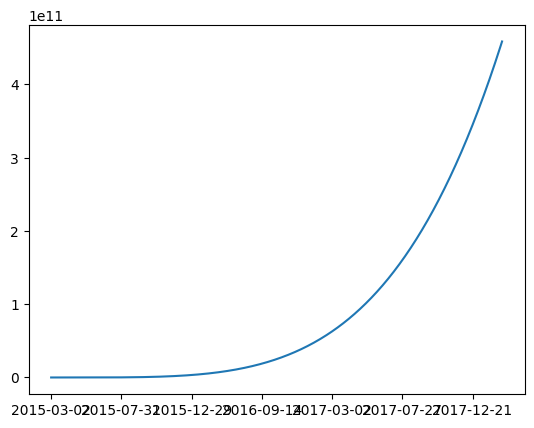

In [35]:
from matplotlib import pyplot as plt   # 导入matplotlib
stock_rise = stock_rise.cumsum()
stock_rise.plot()       # 累加求和的图像 pandas可以画比较简单的图像   默认是折线图
plt.show()

In [11]:
# 16-5-5-6 自定义函数运算
type(data[['open']])   # pandas.core.frame.DataFrame
data[['open','close']].apply(lambda x:x.max()-x.min(),axis=0)   # 求两列中 最大值与最小值之差 

open     22.74
close    22.85
dtype: float64